#**COMP 551 Assignment 1: Bike Sharing Regression**

*Group 3: Barry Zhang, Maeve Côté, Nick Belev*

# Setup

In [ ]:
import numpy as np
import scipy.stats as stats
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

**1.1: Load and Inspect Data**

In [ ]:
# Fetch dataset.
target_dir = "sample_data"
file_path = os.path.join(target_dir, 'day.csv')
if not os.path.exists(file_path):
  # Download the zip file from UCI Repository.
  !wget -N -P {target_dir} "https://archive.ics.uci.edu/ml/machine-learning-databases/00275/Bike-Sharing-Dataset.zip"

  # Unzip ONLY the day.csv file.
  !unzip -o -j "{target_dir}/Bike-Sharing-Dataset.zip" "day.csv" -d {target_dir}
  print("Dataset downloaded and extracted successfully.\n\n")

# Load the data.
bike_dataset = pd.read_csv(file_path)

features = bike_dataset.columns

print(f"There are {len(features)} features in this dataset.")
print(f"There are {len(bike_dataset)} samples in this dataset.\n")

print("Feature names:")
for feature in features:
    print(f" - {feature}")

print("\nData types and non-null counts:")
bike_dataset.info()


There are 16 features in this dataset.
There are 731 samples in this dataset.

Feature names:
 - instant
 - dteday
 - season
 - yr
 - mnth
 - holiday
 - weekday
 - workingday
 - weathersit
 - temp
 - atemp
 - hum
 - windspeed
 - casual
 - registered
 - cnt

Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 731 entries, 0 to 730
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     731 non-null    int64  
 1   dteday      731 non-null    object 
 2   season      731 non-null    int64  
 3   yr          731 non-null    int64  
 4   mnth        731 non-null    int64  
 5   holiday     731 non-null    int64  
 6   weekday     731 non-null    int64  
 7   workingday  731 non-null    int64  
 8   weathersit  731 non-null    int64  
 9   temp        731 non-null    float64
 10  atemp       731 non-null    float64
 11  hum         731 non-null    float64
 12  windspeed   731 non-null  

#Data Cleaning, Preprocessing and Splitting

**1.2: Clean and Preprocess Data**

**Goals:**
*   Remove redundant/irrelevant data.
*   Standardize and normalize the continuous features.
*   Apply 'One-Hot' encoding for categorical features.
*   Split the data set into 'training' and 'test' sets.
*   Add a column of 1's to prepare for linear regression.

**Features to Remove:**

The following features should be disregarded for training purposes:
*   `instant` (the row identifier as an explicit data element is unnecessary and already handled by the dataframe).
*   `dteday` (redundant and hard to numerify without library. `mnth`, `yr`, `weekday` are available instead).
*   `registered` and `casual` (these sum to our target `cnt`, so we remove to protect against training data leakage).
*   `temp` (`temp` and `atemp` are redundant and have 0.992 correlation, whereas `atemp` has slightly higher correlation with the target `cnt`).




In [ ]:
# Variables
features_to_drop = ['instant', 'dteday', 'temp', 'casual', 'registered']
categorical_features = ['season', 'weathersit', 'mnth', 'weekday']
continuous_features = ['atemp', 'hum', 'windspeed']
target = 'cnt'
training_percentage = 0.8 # Classic 80-20 split

# Ensure reproducibility of this "random" split
seed = 551
np.random.seed(seed)

# Drop irrelevant / leakage features
clean_data = bike_dataset.drop(columns=features_to_drop)

# Separate features and target
X = clean_data.drop(columns=[target])
y = clean_data[target].values

# One-hot encoding
X = pd.get_dummies(X, columns=categorical_features, drop_first=True)

# Train/test split by shuffling in-place and cutting the deck in two (80-20)
indices = np.arange(len(X))
np.random.shuffle(indices)

split_id = int(len(X) * training_percentage)
train_idx, test_idx = indices[:split_id], indices[split_id:]

X_train_pd = X.iloc[train_idx].copy()
y_train = y[train_idx]
X_test_pd = X.iloc[test_idx].copy()
y_test = y[test_idx]

To elaborate on the One-Hot Encoding, take the Seasons categorical column for example.  Split it into 4 binary (0 or 1) columns corresponding to each season.  We can safely drop one columns and leave the remaining 3, since if all three columns are 0, the season must be the 4th (implicit) season.  This also breaks the multicolinearity that would otherwise result.  The same approach is performed on months and weekdays.

In [ ]:
# Normalize all distributions of continuous features to have mean = 0, Std. Dev. = 1
for feat in continuous_features:
    mean = X_train_pd[feat].mean()
    std = X_train_pd[feat].std()

    X_train_pd[feat] = (X_train_pd[feat] - mean) / std
    X_test_pd[feat] = (X_test_pd[feat] - mean) / std

We observed approximately mound-shaped distributions and operate under the assumption that continuous features approximately obey the central limit theorem, as we observe with the `cnt` variable.  This justifies performing Standard-Normalization, as well as for numerical stability.

# Data Exploration

**1.3: Exploratory Analysis and Data Visualization**

This section will showcase the behavior of the data, datatypes, and various trends.  This will reveal useful data features, handle malformed values, scale and normalize a feature's distribution, and numerify categorical features.

This exploration will inform the decisions behind data cleaning / preprocessing.

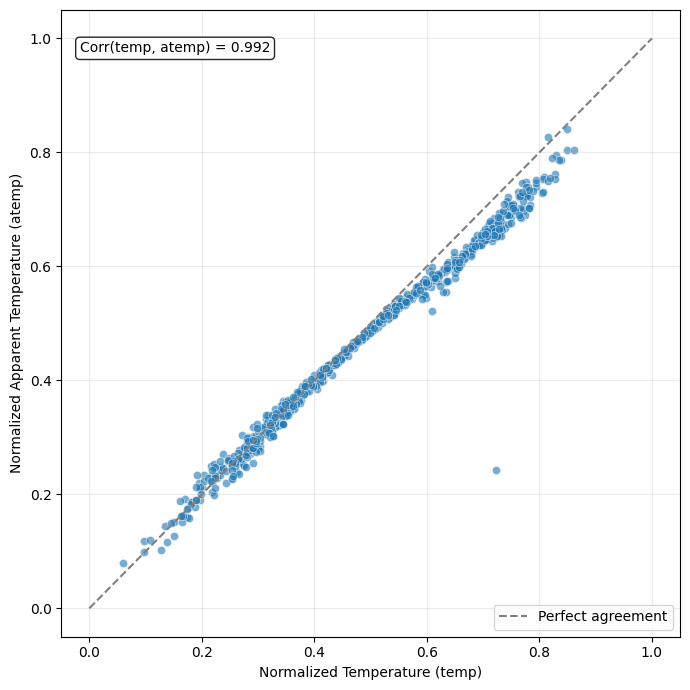

Correlation with cnt → temp: 0.6275, atemp: 0.6311


In [ ]:
# Compare 'temp' and 'atemp' to assess redundancy

corr_temp_atemp = bike_dataset['temp'].corr(bike_dataset['atemp'])
corr_temp_cnt   = bike_dataset['temp'].corr(bike_dataset['cnt'])
corr_atemp_cnt  = bike_dataset['atemp'].corr(bike_dataset['cnt'])

plt.figure(figsize=(7, 7))

sns.scatterplot(
    data=bike_dataset,
    x='temp',
    y='atemp',
    alpha=0.6,
    s=35,
    color='tab:blue'
)

# Perfect agreement reference
plt.plot([0, 1], [0, 1],
         linestyle='--', color='gray',
         linewidth=1.5, label='Perfect agreement')

# plt.title('Temp vs Apparent Temp', fontsize=13)
plt.xlabel('Normalized Temperature (temp)')
plt.ylabel('Normalized Apparent Temperature (atemp)')

plt.text(
    0.03, 0.95,
    f'Corr(temp, atemp) = {corr_temp_atemp:.3f}',
    transform=plt.gca().transAxes,
    va='top',
    fontsize=10,
    bbox=dict(boxstyle='round', facecolor='white', alpha=0.85)
)

plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

print(f"Correlation with cnt → temp: {corr_temp_cnt:.4f}, atemp: {corr_atemp_cnt:.4f}")

As per the Q-Q plot, `temp` and `atemp` are almost perfectly correlated (~ 0.992), making one of them redundant. We will keep `atemp`, which correlates slightly better (0.6311 vs. 0.6275) with the target, and can drop `temp`.  We notice one outlier point at around `temp` = 0.72, `atemp` = 0.22, indicating a case where feeling temperature was much lower than true temperature (slightly decreasing overall correlation from 1).

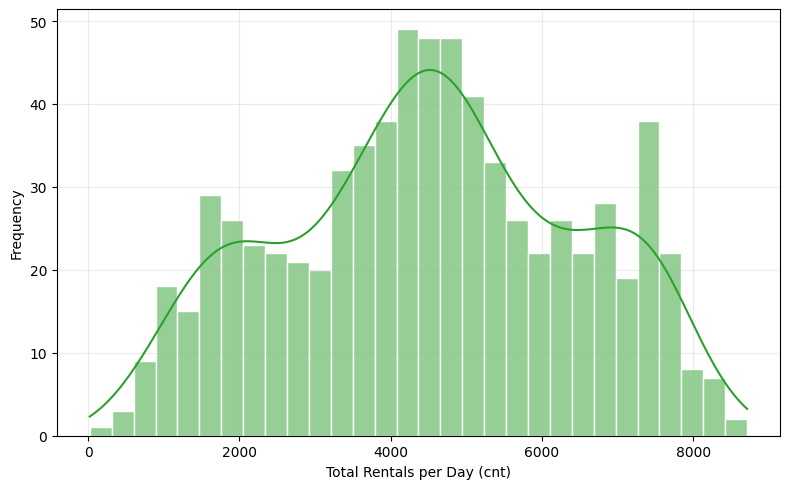

Mean   of cnt: 4504.35
Median of cnt: 4548.00


In [ ]:
# Distribution of the target variable (cnt)
plt.figure(figsize=(8, 5))

sns.histplot(
    bike_dataset['cnt'],
    bins=30,
    kde=True,
    color='tab:green',
    edgecolor='white'
)

# plt.title('Distribution of Daily Bike Rentals', fontsize=13)
plt.xlabel('Total Rentals per Day (cnt)')
plt.ylabel('Frequency')

plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

mean_cnt = bike_dataset['cnt'].mean()
median_cnt = bike_dataset['cnt'].median()
mode_cnt = bike_dataset['cnt'].mode()[0]

print(f"Mean   of cnt: {mean_cnt:.2f}")
print(f"Median of cnt: {median_cnt:.2f}")

The distribution of daily bike rentals ranges between observations of 0 and 8000+ rentals per day, whereas the frequency of observations ranges between 0 and 50 (with the highest frequency achieved around the center of the distribution, where the mean = median, approx. ).  Note this distribution while symmetric and bell shaped around the mean (4500, approx.), has two smaller half-bells (at 2000 and 7000 daily rentals, approx.).  Nonetheless, this distribution is mound shaped and can be approximated as Normal.

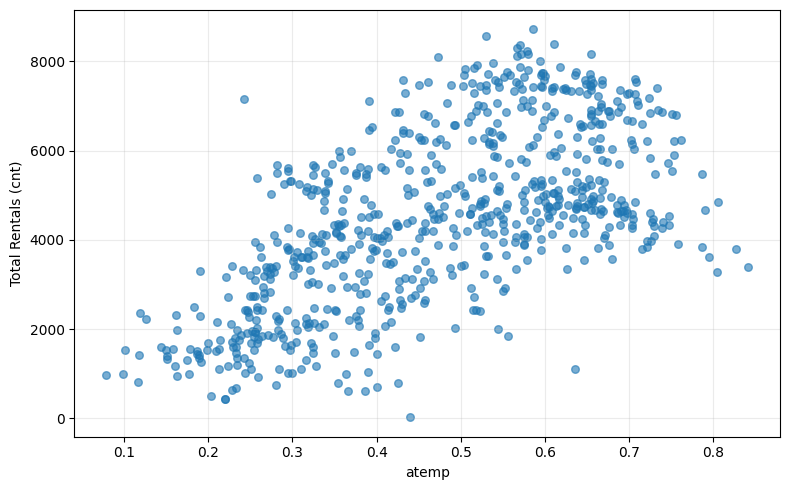

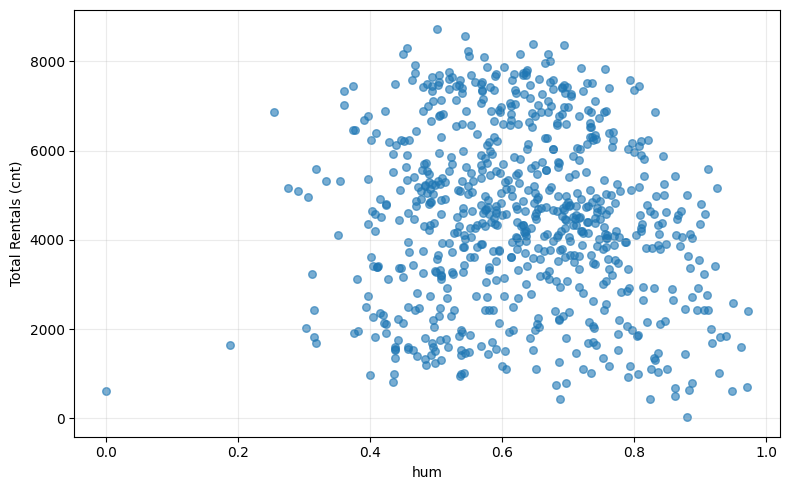

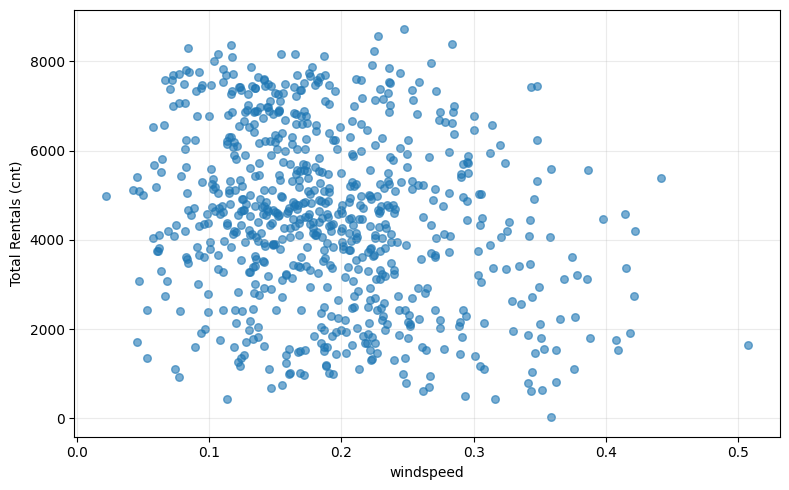

In [ ]:
# Relationship between continuous features and target (cnt)

features_to_plot = ['atemp', 'hum', 'windspeed']

for feature in features_to_plot:
    plt.figure(figsize=(8, 5))

    plt.scatter(
        bike_dataset[feature],
        bike_dataset['cnt'],
        alpha=0.6,
        s=30,
        color='tab:blue'
    )

    # plt.title(f'{feature} vs Daily Bike Rentals', fontsize=13)
    plt.xlabel(feature)
    plt.ylabel('Total Rentals (cnt)')

    plt.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

Of all these scatterplots, visually the one with the most plausible linear correlation is `atemp` (normalized feeling temperature) vs. Daily Bike Rentals (`cnt`).  Wind speed and humidity as x-axis features seem to yield random noise and low explainability for total rentals.

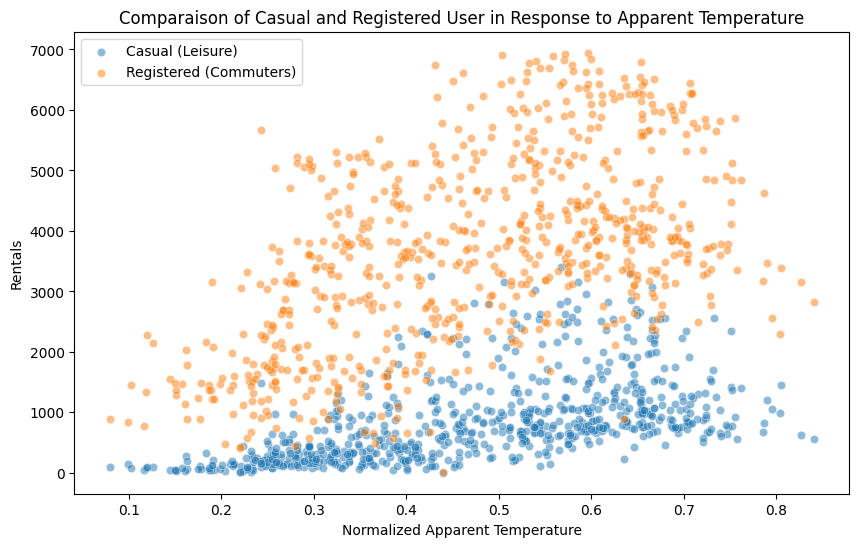

In [ ]:
# Analyse the 'casual' vs 'registered' variables.
# Compare with temperature.
plt.figure(figsize=(10, 6))
sns.scatterplot(x='atemp', y='casual', data=bike_dataset, label='Casual (Leisure)', alpha=0.5)
sns.scatterplot(x='atemp', y='registered', data=bike_dataset, label='Registered (Commuters)', alpha=0.5)

plt.title('Comparaison of Casual and Registered User in Response to Apparent Temperature')
plt.xlabel('Normalized Apparent Temperature')
plt.ylabel('Rentals')
plt.legend()
plt.show()

The registered users display more variability as to their renting quantity in relation to the normalized feeling temperature.  Specifically, colder days (towards 0.0) seem to have less bike rentals than warmer days (towards 1.0).  However, the registered commuters (perhaps they are motivated to get better use of their subscription) are less sensitive to temperature (lower visual correlation between `atemp` and `cnt`).

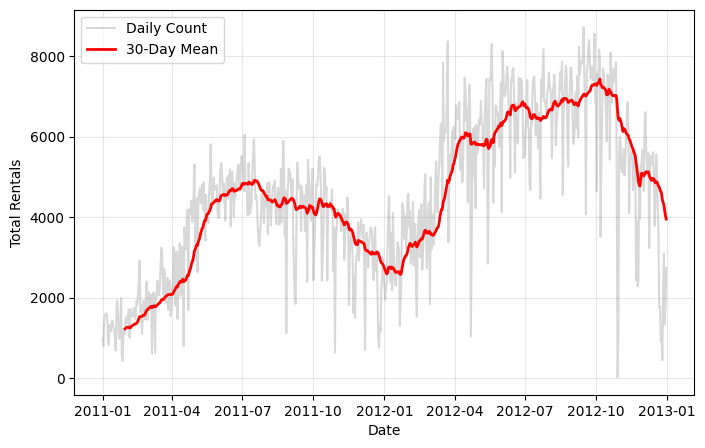

In [ ]:
# Gaining insight on why the year variable is useful and should be included in the data.
# Convert 'dteday' to datetime for plotting
plot_dataset = bike_dataset.copy()
plot_dataset['dteday'] = pd.to_datetime(plot_dataset['dteday'])

# Plot.
plt.figure(figsize=(8, 5))
plt.plot(plot_dataset['dteday'], plot_dataset['cnt'], label='Daily Count', alpha=0.3, color='gray')
plt.plot(plot_dataset['dteday'], plot_dataset['cnt'].rolling(window=30).mean(),
         label='30-Day Mean', color='red', linewidth=2)

# plt.title('Variation of Bike Users Over the Years (2011-2012)')
plt.xlabel('Date')
plt.ylabel('Total Rentals')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

The above trend is expected, with numbers generally climbing in the warm months and declining in the winter months (when biking may be cold and unpleasant).  Even with this cyclicality, there is a rise in the overall popularity (ex. annual range of values) for rentals.

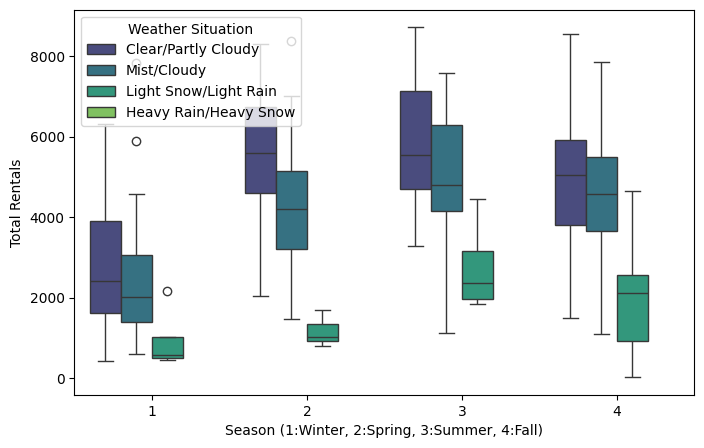

In [ ]:
# Observing the impact of weather on the use of bike rentals over seasons.
# Converting the numbers in meaningful data.
weather_map = {
    1: 'Clear/Partly Cloudy',
    2: 'Mist/Cloudy',
    3: 'Light Snow/Light Rain',
    4: 'Heavy Rain/Heavy Snow'
}
plot_dataset['weather_desc'] = plot_dataset['weathersit'].map(weather_map)

# Plot.
plt.figure(figsize=(8, 5))
sns.boxplot(x='season', y='cnt',
            hue='weather_desc',
            data=plot_dataset,
            palette='viridis',
            hue_order=['Clear/Partly Cloudy', 'Mist/Cloudy', 'Light Snow/Light Rain', 'Heavy Rain/Heavy Snow'])

# plt.title('Impact of Weather Severity across Seasons')
plt.xlabel('Season (1:Winter, 2:Spring, 3:Summer, 4:Fall)')
plt.ylabel('Total Rentals')
plt.legend(title='Weather Situation', loc='upper left')

plt.show()

These trends are expected and explainable.  Overall the summer sees most rentals and the winter sees the least.  Moreover, favorable weather (clear and sunny) sees more rentals than poor weather (rainy and cloudy), within each season.

## "Creative" Analysis

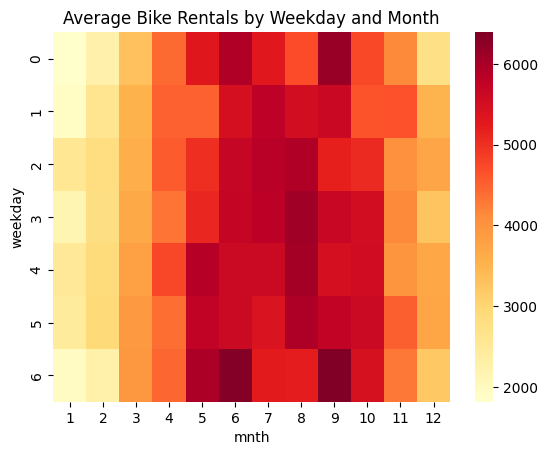

In [ ]:
pivot = bike_dataset.pivot_table(
    values='cnt',
    index='weekday',
    columns='mnth',
    aggfunc='mean'
)

sns.heatmap(pivot, cmap='YlOrRd')
plt.title('Average Bike Rentals by Weekday and Month')
plt.show()

This "heat map" matrix depicts the correlation between all (month, weekday) pairs and their corresponding numbers of bike rentals.  This clearly identifies the greater popularity of renting during the warmer months (late Spring (5) - Fall (10)).  

As for the weekday trend, during warmer months, weekends (6 (Saturday) and 0 (Sunday)) seem to demand more bikes (see months 6 and 9).  Perhaps this is due to leisure activities. Though, overall, there is significant noise and less behavior explainability from weekdays alone.

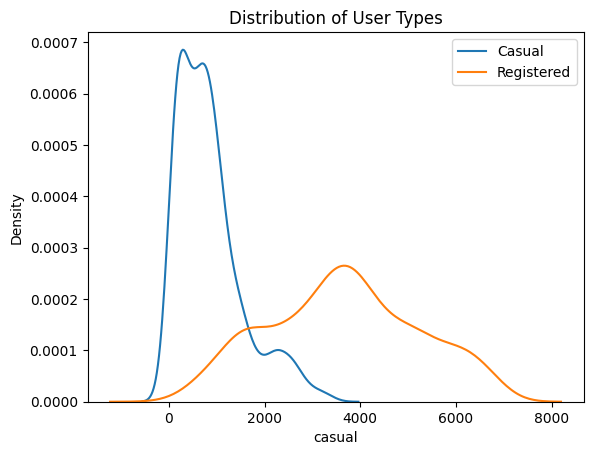

In [ ]:
sns.kdeplot(bike_dataset['casual'], label='Casual')
sns.kdeplot(bike_dataset['registered'], label='Registered')
plt.legend()
plt.title('Distribution of User Types')
plt.show()

In [ ]:
summer = bike_dataset[bike_dataset['season'] == 3]
summer['temp'].corr(summer['cnt'])

np.float64(-0.03281875789906803)

An interesting observation: Given that the season is summer, the correlation between temperature and bike rentals drops to a near 0 (and in fact slightly negative) value.  This indicates that seasonality is a strong explainer of rental demand.  Once `season = summer` is considered, temperature doesn't further explain variation in rental demand (perhaps due to summer's already strong correlation with "good"/warmer biking temperatures).

# Implementing Linear Regression Analytically

**2.1: Linear Regression Formula and Model**

In [ ]:
class LinearRegressionClosedForm:
    def __init__(self):
        self.w = None # the estimated regression coefficient

    def fit(self, X, y):
        XtX = X.T @ X # X transposed matrix-multiplied with X
        Xty = X.T @ y # X^T . y-vector
        self.w = np.linalg.solve(XtX, Xty) # w = ((X^TX)^(-1)).((X^T)y)

    def predict(self, X):
        return X @ self.w # X.w is effectively our y_hat regression estimates for all X rows of features

**2.2: Train / Test Splitting**

In [ ]:
X_train_pd = X_train_pd.astype(float)
X_test_pd = X_test_pd.astype(float)

# We left-pad the rows of features with a column of 1's for the intercept / bias term.
X_train = np.c_[np.ones(len(X_train_pd)), X_train_pd.values]
X_test = np.c_[np.ones(len(X_test_pd)), X_test_pd.values] # Pad with 1's

**2.3: MSE Evaluation Metric**

In [ ]:
def mean_squared_error(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2) # Equivalent to (1/n) * Sum[1 to n][(y-y_hat)^2] or average sum of squares.

In [ ]:
# Initialize and train the model
model = LinearRegressionClosedForm()
model.fit(X_train, y_train)

# Predictions on training and test sets
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)
# Print out model weight
print(model.w)
print(X_train_pd.columns.tolist())


[ 2039.28403929  2041.02404874  -447.32865627   150.57516461
   755.77320744  -228.28223978  -192.45114774  1090.94738281
   959.53154785  1598.13297522  -489.2215325  -1961.04309318
   207.72546463   611.34018875   271.66784715   711.52068231
   515.67190544   171.10371241   546.73926981  1087.09170804
   592.15614691  -142.64547645   -11.20183957   185.28896605
   251.03096878   303.612586     238.57203234   327.62677954
   536.40569452]
['yr', 'holiday', 'workingday', 'atemp', 'hum', 'windspeed', 'season_2', 'season_3', 'season_4', 'weathersit_2', 'weathersit_3', 'mnth_2', 'mnth_3', 'mnth_4', 'mnth_5', 'mnth_6', 'mnth_7', 'mnth_8', 'mnth_9', 'mnth_10', 'mnth_11', 'mnth_12', 'weekday_1', 'weekday_2', 'weekday_3', 'weekday_4', 'weekday_5', 'weekday_6']


In [ ]:
# Calculate and output the MSE

train_mse = mean_squared_error(y_train, y_train_pred)
test_mse = mean_squared_error(y_test, y_test_pred)

print(f"Training MSE: {train_mse:.2f}")
print(f"Test MSE: {test_mse:.2f}")

Training MSE: 564867.07
Test MSE: 626918.84


Note that while these MSE's are large numbers, they measure a 2-dimensional space (due to the square).  If we take `RMSE (Root Mean Squared Error = (MSE)^(1/2))` we can see the variability between estimated rentals and actual rentals (in 1-dimensional space: distance / deviation).

`Training RMSE = 725.21` (rentals approx.)

`Test RMSE: 889.47` (rentals approx.)

This is analogous to a standard deviation metric, for how far off the actual rentals count on a particular day is from the linear regression estimate.  

The training set's RMSE and MSE are markedly lower than their test set counterparts.  This is explained by the fact that the regression hyperplane was fitted using the training set to minimize the Sum of Squares loss function with respect to those exact points, making it highly unlikely that unseen data would fit better into the trend than the training data.

Judging from pure RMSE alone, given that rentals are in the scale of thousands (0 - 8000), this level of error is acceptable and indicates a strong linear relationship between the chosen features and `cnt` (daily bike rentals).

# Modifying the Regression with Non Linear Feature Engineering

**3.1: Feature Engineering**

Here we will explore 3 non-linear modifications to our existing multivariable linear regression model.  Firstly, we will modify the `atemp` term to be `atemp^2`, a polynomial term.  Secondly, we will introduce an interaction term between `atemp` and `mnth_i` as: `atemp x mnth_i`.  Thirdly, we log-transform `windspeed` as ( $\log(\texttt{windspeed} + \texttt{min_value}$) ). Since `windspeed` is standardized and may take negative values, the additive shift ensures the logarithm is well-defined for all observations.

In each of these cases we aim to explore whether the engineered feature offers better explanatory power for the number of bikes that get rented daily, `cnt`.  This can be gauged by whether the MSE (Training and Test) increased (worsens) or decreases (improves).  In theory, a lower MSE would indicate we developed a better fitting  model.

**Polynomial Term Model:** Incorporating `atemp^2` under the assumption that warmer weather sees a quadratically proportional increase in bike rentals.

In [ ]:
X_train_poly_pd = X_train_pd.copy()
X_test_poly_pd = X_test_pd.copy()

# Add polynomial term (atemp^2).
# Note: Squaring atemp's distribution will un-standardize the term by making all negatives positive
# Though, the values will still be consistent and safe for use in the regression model
# Mean will remain 0, and Std. Dev. will remain at 1.
X_train_poly_pd['atemp_sq'] = X_train_poly_pd['atemp'] ** 2
X_test_poly_pd['atemp_sq'] = X_test_poly_pd['atemp'] ** 2

X_train_poly = np.c_[np.ones(len(X_train_poly_pd)), X_train_poly_pd.values]
X_test_poly = np.c_[np.ones(len(X_test_poly_pd)), X_test_poly_pd.values]

In [ ]:
# Create and fit our new regression instance
poly_model = LinearRegressionClosedForm()
poly_model.fit(X_train_poly, y_train)
# Print out model weight
print(poly_model.w)
# Run predictions on both datasets
y_train_poly_pred = poly_model.predict(X_train_poly)
y_test_poly_pred = poly_model.predict(X_test_poly)

[ 2627.34214797  1994.84944449  -769.94482095  -218.80660187
   577.30557841  -258.5945197   -192.12701829  1013.11003107
  1126.36880487  1525.6651377   -502.75938494 -2015.50617206
   -43.40669316   223.45717305  -148.23304106   531.90487077
   543.80320754   482.42547427   529.66652968   799.70784852
   201.24292491  -529.55950354  -312.2965948    522.71429211
   595.36873927   662.9198214    606.23316879   691.8388477
   517.44619923  -364.99551539]


In [ ]:
# Obtain MSE for our new model:
train_mse_poly = mean_squared_error(y_train, y_train_poly_pred)
test_mse_poly = mean_squared_error(y_test, y_test_poly_pred)

print("Polynomial Model (atemp^2)")
print(f"Training MSE: {train_mse_poly:.2f}")
print(f"Test MSE: {test_mse_poly:.2f}")

Polynomial Model (atemp^2)
Training MSE: 498012.16
Test MSE: 585921.88


**Interaction Term Model:** Incorporating an interaction between the two weather features `atemp` and `mnth_i` as: `atemp x mnth_i`.  This models the intuition that a "good" month and "good" temperature may have extra synergy conducive to more rentals, and that a "good" month and "bad" temperature should be a penalty, and not partially "cancel out" as they would if the terms were just linearly added.

In [ ]:
# Define the columns to interact with (Feb through Dec)
# We exclude mnth_1 because it is the baseline
month_cols = [f'mnth_{i}' for i in range(2, 13)]

X_train_inter_pd = X_train_pd.copy()
X_test_inter_pd = X_test_pd.copy()

# Loop to create 'atemp * mnth' interaction terms
for col in month_cols:
    new_col_name = f'atemp_x_{col}'

    # Check if the month column actually exists in your dataframe
    if col in X_train_inter_pd.columns:
        X_train_inter_pd[new_col_name] = X_train_inter_pd['atemp'] * X_train_inter_pd[col]
        X_test_inter_pd[new_col_name] = X_test_inter_pd['atemp'] * X_test_inter_pd[col]
    else:
        print(f"Skipping {col} (Not found in data)")

# Add bias and Convert to Matrix
X_train_inter = np.c_[np.ones(len(X_train_inter_pd)), X_train_inter_pd.values]
X_test_inter = np.c_[np.ones(len(X_test_inter_pd)), X_test_inter_pd.values]

# Fit the Model
inter_model = LinearRegressionClosedForm()
inter_model.fit(X_train_inter, y_train)
# Print out inter model weights
print(inter_model.w)
# Predict
y_train_inter_pred = inter_model.predict(X_train_inter)
y_test_inter_pred = inter_model.predict(X_test_inter)

# Calculate MSE
train_mse_inter = mean_squared_error(y_train, y_train_inter_pred)
test_mse_inter = mean_squared_error(y_test, y_test_inter_pred)

print(f"Interaction Model (atemp x Month)")
print(f"Training MSE: {train_mse_inter:.2f}")
print(f"Test MSE:     {test_mse_inter:.2f}")

[ 2119.64325965  1937.55233524  1080.54439822  1685.69232192
   763.31453164  -298.59454859  -206.98786426   788.39980307
  1183.90026073  1500.32778683  -458.45603564 -2070.72070098
   144.03046198  1149.72352743   608.9919321   1225.38446269
  2634.61606008  3482.08644947  1202.19691207  1336.67709715
   726.78406538   425.60727854   838.71995117 -1461.37533961
 -1363.21933282 -1276.49270384 -1313.32994758 -1202.83088946
   502.26703047   -53.66731237   870.74595549   529.41223167
  -335.2890573  -2018.25442103 -2504.64678239  -810.89622221
  -495.229155     709.05460975   708.03227956   865.89845639]
Interaction Model (atemp x Month)
Training MSE: 408419.68
Test MSE:     515878.63


**Log-transform Term Model:** Taking the log of the `windspeed` into `log(windspeed + min_value)`.  `min_value` being a safety for negative logarithms, and the log relationship demonstrating that beyond a certain windspeed, there are diminishing effects on rental demand.

In [ ]:
# Create Copies
X_train_log_pd = X_train_pd.copy()
X_test_log_pd = X_test_pd.copy()

# Add the minimum value in the data to the prevent taking log of negative values.
# Default to 1 if we encounter some negative value
min_val = X_train_log_pd['windspeed'].min()
shift = abs(min_val) + 1 if min_val < 0 else 1

X_train_log_pd['log_windspeed'] = np.log(X_train_log_pd['windspeed'] + shift)
X_test_log_pd['log_windspeed'] = np.log(X_test_log_pd['windspeed'] + shift)

# Add bias and Convert to Matrix
X_train_log = np.c_[np.ones(len(X_train_log_pd)), X_train_log_pd.values]
X_test_log = np.c_[np.ones(len(X_test_log_pd)), X_test_log_pd.values]

# 4. Fit the Model
log_model = LinearRegressionClosedForm()
log_model.fit(X_train_log, y_train)
# Print Log Model Weights
print(log_model.w)
# 5. Predict
y_train_log_pred = log_model.predict(X_train_log)
y_test_log_pred = log_model.predict(X_test_log)

# 6. Calculate MSE
train_mse_log = mean_squared_error(y_train, y_train_log_pred)
test_mse_log = mean_squared_error(y_test, y_test_log_pred)

print(f"Log-Transform Model (log(windspeed + {shift:.2f}))")
print(f"Training MSE: {train_mse_log:.2f}")
print(f"Test MSE:     {test_mse_log:.2f}")

[ 1740.45617939  2040.79913387 -1218.85149751  -617.69172153
   757.19483061  -228.11745505  -277.99231293  1088.52559898
   955.74822458  1597.73776358  -488.98742259 -1959.26696897
   214.05077386   614.42749516   274.33023798   709.04564634
   513.3364306    167.79469828   549.6603445   1091.30552498
   597.93839551  -135.29000757    -4.08171187   958.01808276
  1019.26067149  1071.32704537  1006.51433816  1097.
   537.24080467   272.23669996]
Log-Transform Model (log(windspeed + 3.13))
Training MSE: 564549.43
Test MSE:     626994.66


**Combining Features**

Given the marginal improvement in MSE from both the polynomial `atemp^2` and the interaction term `atemp x mnth_i` models, we combine them to test whether the MSE is further reduced.

In [ ]:
X_train_combined_pd = X_train_pd.copy()
X_test_combined_pd = X_test_pd.copy()

# Add polynomial term (atemp^2).
X_train_combined_pd['atemp_sq'] = X_train_combined_pd['atemp'] ** 2
X_test_combined_pd['atemp_sq'] = X_test_combined_pd['atemp'] ** 2

# Loop to create 'atemp * mnth' interaction terms
for col in month_cols:
    new_col_name = f'atemp_x_{col}'

    # Check if the month column actually exists in your dataframe
    if col in X_train_inter_pd.columns:
        X_train_combined_pd[new_col_name] = X_train_combined_pd['atemp'] * X_train_combined_pd[col]
        X_test_combined_pd[new_col_name] = X_test_combined_pd['atemp'] * X_test_combined_pd[col]
    else:
        print(f"Skipping {col} (Not found in data)")

# Add bias and Convert to Matrix
X_train_combined = np.c_[np.ones(len(X_train_combined_pd)), X_train_combined_pd.values]
X_test_combined = np.c_[np.ones(len(X_test_combined_pd)), X_test_combined_pd.values]

# Fit the Model
combined_model = LinearRegressionClosedForm()
combined_model.fit(X_train_combined, y_train)
# Print Combined model Weights
print(combined_model.w)
# Predict
y_train_combined_pred = combined_model.predict(X_train_combined)
y_test_combined_pred = combined_model.predict(X_test_combined)

# Calculate MSE
train_mse_combined = mean_squared_error(y_train, y_train_combined_pred)
test_mse_combined = mean_squared_error(y_test, y_test_combined_pred)

print(f"Combinded Polynomial + Interaction Model")
print(f"Training MSE: {train_mse_combined:.2f}")
print(f"Test MSE:     {test_mse_combined:.2f}")

[ 2025.38537686  1939.62892801  6353.95773805  6961.38313614
   600.04647258  -297.04672583  -204.4724444    789.84467137
  1179.397833    1496.9196951   -460.85045349 -2063.65950613
   190.11888255  1248.71842713   711.20555302  1306.24066909
  2655.880344    3451.72732776  1346.95408382  1400.434806
   834.06758758   509.96529186   905.51232643 -6735.90582156
 -6637.32097572 -6551.31947042 -6586.67624121 -6475.11377246
   503.2969875    -61.59637905   -15.21027895   972.89407897
   682.83284353  -103.53829653 -1713.42225822 -2158.36854089
  -613.54443082  -234.34476959   844.48683114   799.64565909
   931.0530268 ]
Combinded Polynomial + Interaction Model
Training MSE: 408134.12
Test MSE:     516100.90


**Final Comparison of All Regression Models**

In [ ]:
# Create a dictionary of the results.
results_data = {
    'Model Variation': [
        'Baseline (Original)',
        'Polynomial (atemp^2)',
        'Interaction (atemp*mnth)',
        'Log-Transform (wind)',
        'Combined (poly & inter)'
    ],
    'Train MSE': [
        train_mse,
        train_mse_poly,
        train_mse_inter,
        train_mse_log,
        train_mse_combined
    ],
    'Test MSE': [
        test_mse,
        test_mse_poly,
        test_mse_inter,
        test_mse_log,
        test_mse_combined
    ]
}

# Convert to DataFrame.
df_results = pd.DataFrame(results_data)

# Add "Improvement vs Baseline" column in percentage.
df_results['Test Improvement (%)'] = (
    (df_results['Test MSE'] - test_mse) / test_mse * 100
)

# Formatting.
pd.options.display.float_format = '{:,.0f}'.format

print("\n" + "="*60)
print("             Feature Engineering Results Table")
print("="*60)
print(df_results.to_string(index=False, formatters={
    'Train MSE': '{:,.0f}'.format,
    'Test MSE': '{:,.0f}'.format,
    'Test Improvement (%)': '{:+.2f}%'.format
}))
print("-" * 60)


             Feature Engineering Results Table
         Model Variation Train MSE Test MSE Test Improvement (%)
     Baseline (Original)   564,867  626,919               +0.00%
    Polynomial (atemp^2)   498,012  585,922               -6.54%
Interaction (atemp*mnth)   408,420  515,879              -17.71%
    Log-Transform (wind)   564,549  626,995               +0.01%
 Combined (poly & inter)   408,134  516,101              -17.68%
------------------------------------------------------------


The results indicate that the interaction term (`atemp x month`) yielded the most significant improvement, followed closely by the polynomial term (atemp²). However, the Combined Model exhibited a higher Test MSE compared to the individual models. This suggests that simultaneously including both engineered features created excess complexity (that doesn't explain the true underlying model).  Furthermore, the Combined Model had the lowest Training MSE, and yet a higher Test MSE than the Interaction model alone, indicating overfitting.

Additionally, the log-transformation of windspeed proved ineffective. This is likely because the baseline correlation between windspeed and bike rentals is relatively weak, or the relationship is sufficiently linear that a logarithmic scale offers no explanatory advantage.

# Analysis


**Error Analysis:**

To validate the assumptions of the linear regression model, we analyse the distribution of the residuals. The Ordinary Least Squares (OLS) method assumes that the underlying error terms follow a Gaussian (Normal) distribution. To verify this, we visualize the residuals using a histogram and a Quantile-Quantile (Q-Q) plot.

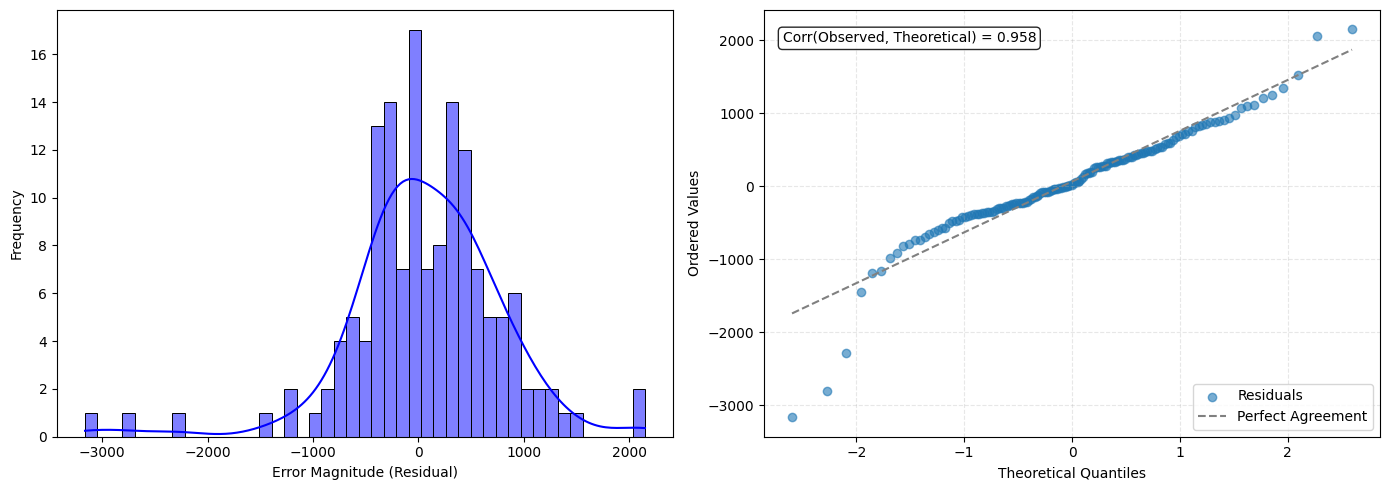

In [ ]:
# Noise = True Value - Predicted Value
residuals = y_test - y_test_inter_pred

plt.figure(figsize=(14, 5))
# Histogram of the residuals.
plt.subplot(1, 2, 1)
sns.histplot(residuals, kde=True, bins=45, color='blue', edgecolor='black')
# plt.title('Distribution of Residuals (Histogram)')
plt.xlabel('Error Magnitude (Residual)')
plt.ylabel('Frequency')

# Comparaison to the ideal normal distribution.
# osm = Theoretical Quantiles (X-axis)
# osr = Ordered Responses (Y-axis)
# slope, intercept, r = Regression parameters for the line
plt.subplot(1, 2, 2)
(osm, osr), (slope, intercept, r) = stats.probplot(residuals, dist="norm", plot=None)

plt.scatter(osm, osr, alpha=0.6, label='Residuals')

plt.plot(osm, slope * osm + intercept,
         color='gray',
         linestyle='--',
         linewidth=1.5,
         label='Perfect Agreement'
)

plt.text(0.03, 0.95,
         f'Corr(Observed, Theoretical) = {r:.3f}',
         transform=plt.gca().transAxes,
         va='top',
         fontsize=10,
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.85)
)

# plt.title(f'Quantile-Quantile (Q-Q) Plot')
plt.xlabel('Theoretical Quantiles')
plt.ylabel('Ordered Values')
plt.grid(True, linestyle='--', alpha=0.3)
plt.legend()

plt.tight_layout()
plt.show()

The histogram exhibits a relatively symmetric bell shape distribution, characteristic of a Normal distribution.  Note though that extreme values of very negative error magnitude are observed.  Some, multiple standard deviations away from the apparent mean.  This observation is corroborated by the Q-Q plot, where the residuals align fairly closely with the theoretical reference line (`R = 0.954`), indicating that the normality can be assumed.  Note that the Q-Q plot also features the left-tail outliers observed in the histogram.

**Model Explanation:**

We next inspect the Baseline Model.  Given the model's nature as a linear equation, the calibrated weights can be interpreted to see the coefficient of impact or "explainability" that the best fitting model has assigned to each variable, to estimate the total bike rentals.

In [ ]:
# Associate weights to their features.
feature_names = list(X_train_pd.columns)

feature_names.insert(0, 'Bias (Intercept)')

if model.w.ndim > 1 and model.w.shape[1] == 2:
    columns = ['Casual Users', 'Registered Users']
else:
    columns = ['Weight']

# Create the dataframe
weights_df = pd.DataFrame(model.w, index=feature_names, columns=columns)

print("--- Linear Regression Coefficients ---")
print(weights_df.round(2))

--- Linear Regression Coefficients ---
                  Weight
Bias (Intercept)   2,039
yr                 2,041
holiday             -447
workingday           151
atemp                756
hum                 -228
windspeed           -192
season_2           1,091
season_3             960
season_4           1,598
weathersit_2        -489
weathersit_3      -1,961
mnth_2               208
mnth_3               611
mnth_4               272
mnth_5               712
mnth_6               516
mnth_7               171
mnth_8               547
mnth_9             1,087
mnth_10              592
mnth_11             -143
mnth_12              -11
weekday_1            185
weekday_2            251
weekday_3            304
weekday_4            239
weekday_5            328
weekday_6            536


The table above reveals that Year and Weather Severity are the dominant factors (magnitude-wise) in determining the number of rentals for a given day. This economic sector has experienced and continues to undergo massive year-over-year growth (+2041 rentals/day on average). Conversely, adverse weather (weathersit_3) acts as a severe deterrent on a daily scale, reducing daily traffic by nearly 2,000 riders. Temperature (atemp) is positively correlated with demand, while humidity and windspeed act as minor deterrents.

These results corroborate with the intuition that we had from the graph made in Part 1, confirming the validity of this regression approach.